In [24]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
tickers = ["CW8.PA", "IUSQ.DE", "PSP5.PA", "PUST.PA", "ETZ.PA",
           "AI.PA", "TTE.PA", "SAN.PA", "BN.PA", "ORA.PA", "ENGI.PA"]

prix = yf.download(tickers, start="2021-01-01", end="2026-10-28")["Close"]
prix.head()

[*********************100%***********************]  11 of 11 completed


Ticker,AI.PA,BN.PA,CW8.PA,ENGI.PA,ETZ.PA,IUSQ.DE,ORA.PA,PSP5.PA,PUST.PA,SAN.PA,TTE.PA
Date,,,,,,,,,,,
2021-01-04,91.637169,44.499310,327.290100,8.304384,11.346,51.560001,6.915305,24.906000,41.040001,61.398094,24.755537
2021-01-05,90.663383,44.662907,327.683990,8.181163,11.330,51.860001,6.894454,24.945999,41.084999,61.390316,25.406902
2021-01-06,90.864853,45.055553,332.530396,8.511912,11.510,52.410000,7.012607,25.350000,41.195000,61.017258,26.523537
2021-01-07,91.570007,44.352070,334.638489,8.476243,11.532,52.810001,7.165508,25.577999,41.630001,60.403278,26.813419
2021-01-08,92.107277,43.370468,337.027313,8.628647,11.614,53.299999,7.064732,25.684999,42.099998,61.234879,26.831326


In [26]:
print(prix.shape)
print(prix.isna().sum())
print(prix.notna().idxmax())

(1491, 11)
Ticker
AI.PA      0
BN.PA      0
CW8.PA     0
ENGI.PA    0
ETZ.PA     0
IUSQ.DE    9
ORA.PA     0
PSP5.PA    0
PUST.PA    0
SAN.PA     0
TTE.PA     0
dtype: int64
Ticker
AI.PA     2021-01-04
BN.PA     2021-01-04
CW8.PA    2021-01-04
ENGI.PA   2021-01-04
ETZ.PA    2021-01-04
IUSQ.DE   2021-01-04
ORA.PA    2021-01-04
PSP5.PA   2021-01-04
PUST.PA   2021-01-04
SAN.PA    2021-01-04
TTE.PA    2021-01-04
dtype: datetime64[s]


In [27]:
prix = prix.ffill()
rendements = prix.pct_change().dropna()
print(rendements.isna().sum())

Ticker
AI.PA      0
BN.PA      0
CW8.PA     0
ENGI.PA    0
ETZ.PA     0
IUSQ.DE    0
ORA.PA     0
PSP5.PA    0
PUST.PA    0
SAN.PA     0
TTE.PA     0
dtype: int64


In [28]:
vol = rendements.std() * (252 ** 0.5)
print(vol.sort_values(ascending=False))

Ticker
TTE.PA     0.241972
SAN.PA     0.225176
ENGI.PA    0.212510
PUST.PA    0.196598
BN.PA      0.188884
AI.PA      0.184819
ORA.PA     0.170219
PSP5.PA    0.147346
ETZ.PA     0.140923
CW8.PA     0.137582
IUSQ.DE    0.135945
dtype: float64


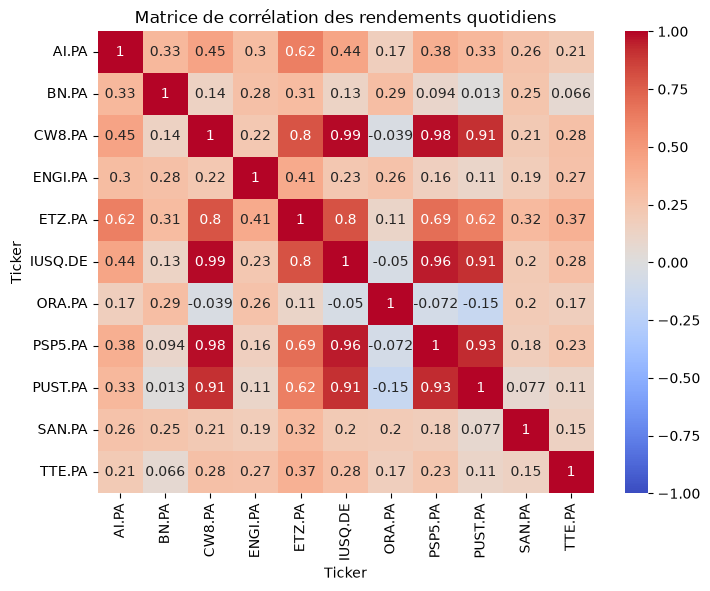

In [29]:
correlations = rendements.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlations, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation des rendements quotidiens")
plt.show()

In [30]:
poids = 0.0909
rendement_ptf = (rendements[["CW8.PA", "IUSQ.DE", "PSP5.PA", "PUST.PA", "ETZ.PA",
           "AI.PA", "TTE.PA", "SAN.PA", "BN.PA", "ORA.PA", "ENGI.PA"]] * poids).sum(axis=1)

vol_ptf = rendement_ptf.std() * (252 ** 0.5)
moyenne_vols = vol[["CW8.PA", "IUSQ.DE", "PSP5.PA", "PUST.PA", "ETZ.PA",
           "AI.PA", "TTE.PA", "SAN.PA", "BN.PA", "ORA.PA", "ENGI.PA"]].mean()

print("Volatilité du portefeuille :", vol_ptf)
print("Moyenne des volatilités   :", moyenne_vols)

Volatilité du portefeuille : 0.10780199475671566
Moyenne des volatilités   : 0.18017936780657653


In [31]:
poids_b1 = pd.Series({
    "CW8.PA": 0.70,    # poche monde (représente DCAM + GPEA)
    "ETZ.PA": 0.15,    # poche Europe (Stoxx 600)
    "AI.PA": 0.025,    # satellites : 15 % répartis sur 6 actions
    "TTE.PA": 0.025,
    "SAN.PA": 0.025,
    "BN.PA": 0.025,
    "ORA.PA": 0.025,
    "ENGI.PA": 0.025,
})

print("Somme des poids :", poids_b1.sum())

rendement_b1 = (rendements[poids_b1.index] * poids_b1).sum(axis=1)
vol_b1 = rendement_b1.std() * (252 ** 0.5)

print("Volatilité B1 :", vol_b1)
print("Volatilité CW8 seul :", vol["CW8.PA"])

Somme des poids : 1.0
Volatilité B1 : 0.12261015758160872
Volatilité CW8 seul : 0.1375815400595267


In [32]:
poids_b2 = pd.Series({
    "CW8.PA": 0.55,    # poche monde (représente DCAM + GPEA)
    "ETZ.PA": 0.15,    # poche Europe (Stoxx 600)
    "AI.PA": 0.05,    # satellites : 15 % répartis sur 6 actions
    "TTE.PA": 0.05,
    "SAN.PA": 0.05,
    "BN.PA": 0.05,
    "ORA.PA": 0.05,
    "ENGI.PA": 0.05,
})

print("Somme des poids :", poids_b2.sum())

rendement_b2 = (rendements[poids_b2.index] * poids_b2).sum(axis=1)
vol_b2 = rendement_b2.std() * (252 ** 0.5)

print("Volatilité B1 :", vol_b2)
print("Volatilité CW8 seul :", vol["CW8.PA"])

Somme des poids : 1.0
Volatilité B1 : 0.11390841285421502
Volatilité CW8 seul : 0.1375815400595267


In [36]:
poids_b3 = pd.Series({
    "CW8.PA": 0.40,    # poche monde (représente DCAM + GPEA)
    "ETZ.PA": 0.20,    # poche Europe (Stoxx 600)
    "AI.PA": 0.0667,    # satellites : 15 % répartis sur 6 actions
    "TTE.PA": 0.0667,
    "SAN.PA": 0.0667,
    "BN.PA": 0.0666,
    "ORA.PA": 0.0667,
    "ENGI.PA": 0.0666,
})

print("Somme des poids :", poids_b3.sum())

rendement_b3 = (rendements[poids_b3.index] * poids_b3).sum(axis=1)
vol_b3 = rendement_b3.std() * (252 ** 0.5)

print("Volatilité B1 :", vol_b3)
print("Volatilité CW8 seul :", vol["CW8.PA"])

Somme des poids : 1.0
Volatilité B1 : 0.11061653584355684
Volatilité CW8 seul : 0.1375815400595267


In [38]:
print(poids_b1)
print(poids_b2)
print(vol_b1, vol_b2)
print(rendement_b1.equals(rendement_b2))
print(dd_b1.min(), dd_b2.min())

CW8.PA     0.700
ETZ.PA     0.150
AI.PA      0.025
TTE.PA     0.025
SAN.PA     0.025
BN.PA      0.025
ORA.PA     0.025
ENGI.PA    0.025
dtype: float64
CW8.PA     0.55
ETZ.PA     0.15
AI.PA      0.05
TTE.PA     0.05
SAN.PA     0.05
BN.PA      0.05
ORA.PA     0.05
ENGI.PA    0.05
dtype: float64
0.12261015758160872 0.11390841285421502
False
-0.17996340201772043 -0.1532083121482003


In [34]:
valeur_b1 = (1 + rendement_b1).cumprod()
dd_b1 = valeur_b1 / valeur_b1.cummax() - 1

print("Drawdown max B1 :", dd_b1.min(), "le", dd_b1.idxmin())

Drawdown max B1 : -0.17996340201772043 le 2025-04-09 00:00:00


In [35]:
valeur_b2 = (1 + rendement_b2).cumprod()
dd_b2 = valeur_b2 / valeur_b2.cummax() - 1

print("Drawdown max B2 :", dd_b2.min(), "le", dd_b2.idxmin())

Drawdown max B2 : -0.1532083121482003 le 2025-04-09 00:00:00


In [39]:
valeur_b3 = (1 + rendement_b3).cumprod()
dd_b3 = valeur_b3 / valeur_b3.cummax() - 1

print("Drawdown max B3 :", dd_b3.min(), "le", dd_b3.idxmin())

Drawdown max B3 : -0.13793545046600486 le 2025-04-09 00:00:00


In [40]:
dd_a = prix["CW8.PA"] / prix["CW8.PA"].cummax() - 1

print("Drawdown max A (CW8 seul) :", dd_a.min(), "le", dd_a.idxmin())

Drawdown max A (CW8 seul) : -0.21656396541249756 le 2025-04-09 00:00:00


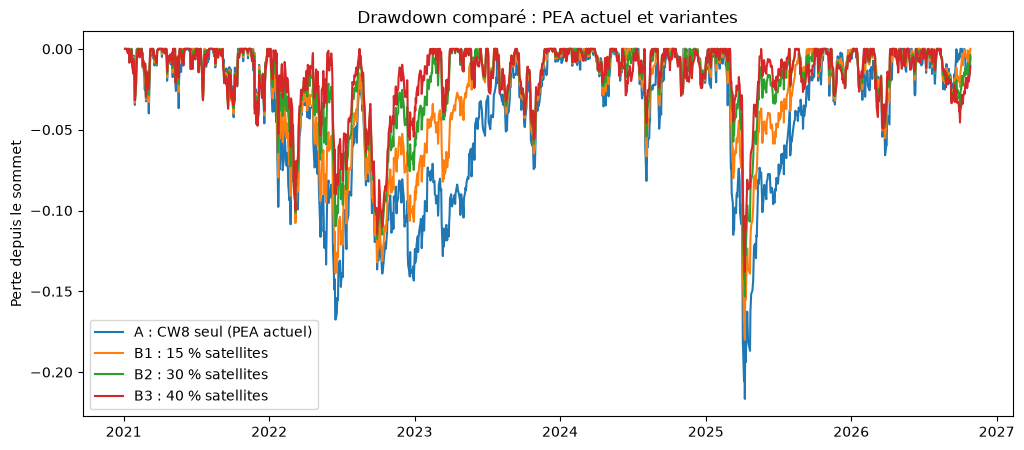

In [41]:
plt.figure(figsize=(12, 5))

plt.plot(dd_a.index, dd_a, label="A : CW8 seul (PEA actuel)")
plt.plot(dd_b1.index, dd_b1, label="B1 : 15 % satellites")
plt.plot(dd_b2.index, dd_b2, label="B2 : 30 % satellites")
plt.plot(dd_b3.index, dd_b3, label="B3 : 40 % satellites")

plt.title("Drawdown comparé : PEA actuel et variantes")
plt.ylabel("Perte depuis le sommet")
plt.legend()
plt.show()

## Conclusion : diversifier un PEA monde

**Question :** ajouter des ETF ou des actions à un PEA composé d'ETF monde (DCAM, GPEA) réduit-il le risque ?

**1. Les ETF américains ne diversifient pas.** CW8 est corrélé à 0,98 avec le S&P 500 et à 0,91 avec le Nasdaq-100. Un portefeuille d'ETF à parts égales est même plus volatil que CW8 seul : c'est un pari sur la tech américaine, pas une diversification.

**2. Les actions européennes peu corrélées diversifient réellement.** Orange, Danone, Sanofi, Engie et TotalEnergies ont une corrélation proche de 0 avec le Nasdaq-100, alors que leur volatilité individuelle est plus élevée que celle de CW8.

**3. Résultats (2021-2026) :**

| Portefeuille | Satellites | Volatilité | Drawdown max |
|---|---|---|---|
| A : CW8 seul | 0 % | 13,8 % | ... |
| B1 | 15 % | 12,3 % | -18,0 % |
| B2 | 30 % | 11,4 % | -15,3 % |
| B3 | 40 % | 11,1 % | -13,8 % |

La volatilité baisse de moins en moins (rendements décroissants de la diversification), mais le drawdown continue de baisser nettement : les satellites amortissent surtout les grosses chutes, et le portefeuille retrouve son sommet plus vite.

**Limites :** une seule période (2021-2026), des corrélations qui peuvent remonter en cas de krach, des poids égaux arbitraires, et le rendement n'a pas encore été comparé. CW8 et IUSQ sont utilisés comme représentants des indices MSCI World et MSCI ACWI, détenus en pratique via DCAM et GPEA.
